## Problema - Red de estaciones de transporte

El ejercicio consiste en representar una red de transporte usando un grafo. La idea es guardar las estaciones y las conexiones entre ellas y luego poder recorrer la red y buscar rutas.


In [ ]:
# @title Ingrese datos
nombre_estudiante = "Juan Pablo Leon Davila" # @param {"type":"string"}
carnet = 1000114216 # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

Una empresa de transporte urbano quiere representar las conexiones entre sus estaciones. Cada estación es un vértice y cada conexión directa es una arista. Como se puede ir en los dos sentidos, el grafo es no dirigido.

La red inicial tiene 7 estaciones: Central, Norte, Museo, Parque, Universidad, Hospital y Terminal. También tiene 7 conexiones. El programa debe permitir:

- Mostrar las conexiones de cada estación usando una lista de adyacencia.
- Recorrer la red con BFS usando una cola y mostrar los niveles.
- Recorrer la red con DFS de forma recursiva.
- Buscar una ruta con el menor número de conexiones entre dos estaciones.
- Agregar una estación nueva con por lo menos dos conexiones sin repetir conexiones.


## 2) Requerimientos **[2 pts]**

### Funcionales
* RF1. Guardar la red como una lista de adyacencia y mostrar las conexiones de cada estación.
* RF2. Hacer un recorrido BFS desde una estación y mostrar el orden y el nivel de cada estación.
* RF3. Hacer un recorrido DFS desde una estación.
* RF4. Dejar que el usuario escoja la estación inicial y avisar si no existe.
* RF5. Buscar con BFS la ruta con menos conexiones entre dos estaciones y mostrar cuántas conexiones tiene.
* RF6. Agregar una estación nueva con mínimo dos conexiones y poder usar los recorridos y la búsqueda de ruta con ella.

### No funcionales

* RNF1. El grafo es no dirigido, por eso cada conexión se guarda en ambos sentidos.
* RNF2. No se aceptan conexiones repetidas ni conexiones de una estación consigo misma.
* RNF3. Una estación se marca como visitada para no recorrerla más de una vez.
* RNF4. BFS se hace con una cola y DFS con recursividad, sin usar librerías que hagan estos recorridos.


## 3) Historias de usuario **[2 pts]**

**HU1**

Como operador, quiero ver cada estación con sus conexiones para saber cómo está formada la red.

- *Criterio:* aparecen las 7 estaciones y las conexiones están en los dos sentidos.

**HU2**

Como analista, quiero hacer BFS y DFS desde la estación que elija para recorrer la red desde distintos puntos.

- *Criterio:* desde Central se obtiene un recorrido válido, se muestran los niveles de BFS y no se repiten estaciones.

**HU3**

Como pasajero, quiero saber cuál es la ruta con menos conexiones entre dos estaciones.

- *Criterio:* de Central a Terminal se obtiene una ruta de 3 conexiones y se informa cuando no existe una ruta.

**HU4**

Como administrador, quiero agregar una estación y conectarla con estaciones que ya existen.

- *Criterio:* la estación es nueva, tiene al menos dos conexiones y no se duplican las conexiones.

**HU5**

Como usuario, quiero que la estación nueva también pueda usarse en BFS, DFS y búsqueda de rutas.

- *Criterio:* después de agregar Aeropuerto se puede recorrer y buscar una ruta que la incluya.


## 4) Diagramas de flujo **[5 pts]**
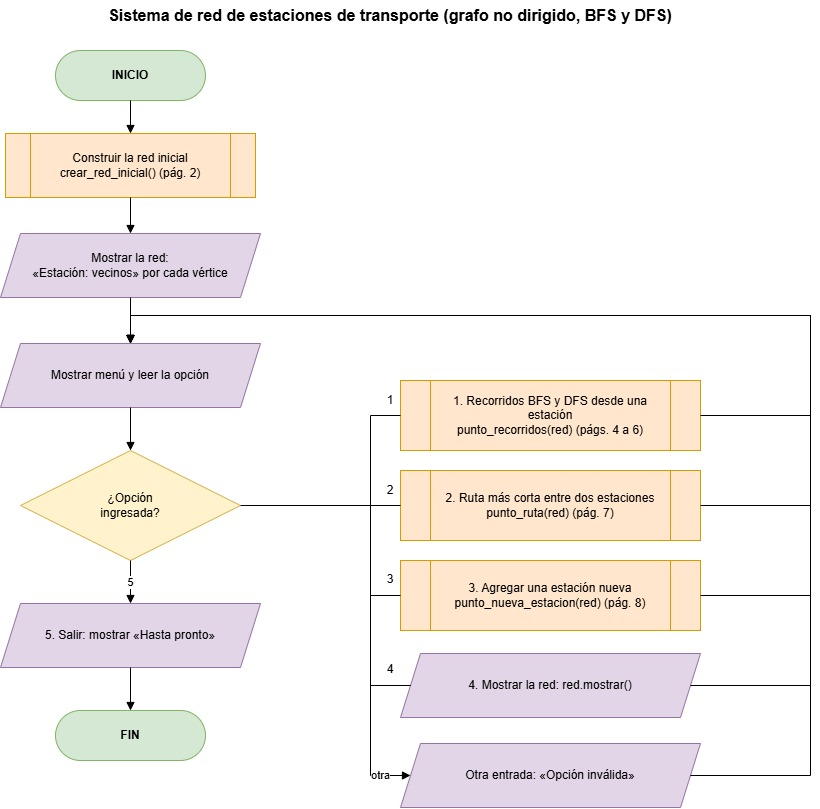


## 5) Análisis de complejidad **[15 pts]**

### BFS

En BFS cada estación se marca como visitada una sola vez. Cuando se saca de la cola se revisan sus vecinos. En un grafo no dirigido se terminan revisando las listas de adyacencia, que en total representan 2E conexiones.

Por eso, usando una cola con salida en tiempo constante, la complejidad es:

**T(n) = O(V + E)**

Donde V es el número de estaciones y E el número de conexiones.

Para la búsqueda de la ruta más corta también se usa BFS, así que su complejidad en el peor caso es **O(V + E)**. Si el destino está directamente conectado al origen, el recorrido termina mucho antes; eso depende de la posición del destino y de los vecinos del origen.

### Gráfica

La gráfica de complejidad se puede representar como una función lineal O(n) si se considera que la cantidad de conexiones crece de forma proporcional a la cantidad de estaciones.


## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [1]:
class Cola:
    def __init__(self):
        self.elementos = []
        self.frente = 0

    def encolar(self, elemento):
        self.elementos.append(elemento)

    def desencolar(self):
        if not self.esta_vacia():
            elemento = self.elementos[self.frente]
            self.frente += 1
            return elemento
        return None

    def esta_vacia(self):
        return self.frente >= len(self.elementos)


class Grafo:
    def __init__(self):
        self.grafo = {}

    def agregar_estacion(self, estacion):
        if estacion not in self.grafo:
            self.grafo[estacion] = []
            return True
        return False

    def agregar_conexion(self, estacion1, estacion2):
        if estacion1 not in self.grafo or estacion2 not in self.grafo:
            return False

        if estacion2 in self.grafo[estacion1]:
            return False

        self.grafo[estacion1].append(estacion2)
        self.grafo[estacion2].append(estacion1)

        return True

    def mostrar_grafo(self):
        for estacion in self.grafo:
            print(estacion + ":", ", ".join(self.grafo[estacion]))

    def bfs(self, inicio):
        if inicio not in self.grafo:
            return None, None

        visitados = set()
        niveles = {}
        recorrido = []
        cola = Cola()

        visitados.add(inicio)
        niveles[inicio] = 0
        cola.encolar(inicio)

        while not cola.esta_vacia():
            actual = cola.desencolar()
            recorrido.append(actual)

            for vecino in self.grafo[actual]:
                if vecino not in visitados:
                    visitados.add(vecino)
                    niveles[vecino] = niveles[actual] + 1
                    cola.encolar(vecino)

        return recorrido, niveles

    def dfs(self, inicio):
        if inicio not in self.grafo:
            return None

        visitados = set()
        recorrido = []

        def recorrer(estacion):
            visitados.add(estacion)
            recorrido.append(estacion)

            for vecino in self.grafo[estacion]:
                if vecino not in visitados:
                    recorrer(vecino)

        recorrer(inicio)

        return recorrido

    def ruta_mas_corta(self, origen, destino):
        if origen not in self.grafo or destino not in self.grafo:
            return None

        visitados = set()
        anterior = {}
        cola = Cola()

        visitados.add(origen)
        anterior[origen] = None
        cola.encolar(origen)

        while not cola.esta_vacia():
            actual = cola.desencolar()

            if actual == destino:
                break

            for vecino in self.grafo[actual]:
                if vecino not in visitados:
                    visitados.add(vecino)
                    anterior[vecino] = actual
                    cola.encolar(vecino)

        if destino not in visitados:
            return None

        ruta = []
        actual = destino

        while actual is not None:
            ruta.append(actual)
            actual = anterior[actual]

        ruta.reverse()

        return ruta


def crear_red():
    grafo = Grafo()

    estaciones = [
        "Central",
        "Norte",
        "Museo",
        "Parque",
        "Universidad",
        "Hospital",
        "Terminal"
    ]

    for estacion in estaciones:
        grafo.agregar_estacion(estacion)

    conexiones = [
        ("Central", "Norte"),
        ("Central", "Museo"),
        ("Norte", "Parque"),
        ("Norte", "Universidad"),
        ("Museo", "Hospital"),
        ("Universidad", "Terminal"),
        ("Hospital", "Terminal")
    ]

    for estacion1, estacion2 in conexiones:
        grafo.agregar_conexion(estacion1, estacion2)

    return grafo


def mostrar_bfs(grafo, inicio):
    recorrido, niveles = grafo.bfs(inicio)

    if recorrido is None:
        print("La estación no existe.")
        return

    print("\nRecorrido BFS:")
    print(" -> ".join(recorrido))

    print("\nNiveles:")

    niveles_maximos = 0

    for estacion in niveles:
        if niveles[estacion] > niveles_maximos:
            niveles_maximos = niveles[estacion]

    for nivel in range(niveles_maximos + 1):
        estaciones = []

        for estacion in niveles:
            if niveles[estacion] == nivel:
                estaciones.append(estacion)

        print("Nivel", nivel, ":", ", ".join(estaciones))


def mostrar_dfs(grafo, inicio):
    recorrido = grafo.dfs(inicio)

    if recorrido is None:
        print("La estación no existe.")
        return

    print("\nRecorrido DFS:")
    print(" -> ".join(recorrido))


def punto_4(grafo):
    inicio = input("\nIngrese la estación inicial: ").strip()

    if inicio not in grafo.grafo:
        print("La estación no existe.")
        return

    mostrar_bfs(grafo, inicio)
    mostrar_dfs(grafo, inicio)


def punto_5(grafo):
    origen = input("\nEstación de origen: ").strip()
    destino = input("Estación de destino: ").strip()

    if origen not in grafo.grafo:
        print("La estación de origen no existe.")
        return

    if destino not in grafo.grafo:
        print("La estación de destino no existe.")
        return

    ruta = grafo.ruta_mas_corta(origen, destino)

    if ruta is None:
        print("No existe una ruta entre las estaciones.")
    else:
        print("\nRuta encontrada:")
        print(" -> ".join(ruta))
        print("Cantidad de conexiones:", len(ruta) - 1)


def punto_6(grafo):
    nueva = input("\nNueva estación: ").strip()

    if nueva in grafo.grafo:
        print("La estación ya existe.")
        return

    conexion1 = input("Conectar con: ").strip()
    conexion2 = input("Conectar con: ").strip()

    if conexion1 not in grafo.grafo or conexion2 not in grafo.grafo:
        print("Una de las estaciones no existe.")
        return

    if conexion1 == conexion2:
        print("Las conexiones deben ser diferentes.")
        return

    grafo.agregar_estacion(nueva)
    grafo.agregar_conexion(nueva, conexion1)
    grafo.agregar_conexion(nueva, conexion2)

    print("\nEstación agregada correctamente.")
    grafo.mostrar_grafo()


def pruebas(grafo):
    recorrido, niveles = grafo.bfs("Central")

    assert recorrido[0] == "Central"
    assert niveles["Central"] == 0
    assert niveles["Norte"] == 1
    assert niveles["Museo"] == 1

    recorrido_dfs = grafo.dfs("Central")
    assert recorrido_dfs[0] == "Central"

    ruta = grafo.ruta_mas_corta("Central", "Terminal")
    assert ruta[0] == "Central"
    assert ruta[-1] == "Terminal"
    assert len(ruta) - 1 == 3

    assert grafo.agregar_conexion("Central", "Norte") == False

    print("\nPruebas realizadas correctamente.")


def main():
    grafo = crear_red()

    print("RED DE ESTACIONES")
    print("\nPunto 1")
    grafo.mostrar_grafo()

    print("\nPunto 2")
    mostrar_bfs(grafo, "Central")

    print("\nPunto 3")
    mostrar_dfs(grafo, "Central")

    print("\nPunto 4")
    punto_4(grafo)

    print("\nPunto 5")
    punto_5(grafo)

    print("\nPunto 6")
    punto_6(grafo)

    pruebas(grafo)


if __name__ == "__main__":
    main()

RED DE ESTACIONES

Punto 1
Central: Norte, Museo
Norte: Central, Parque, Universidad
Museo: Central, Hospital
Parque: Norte
Universidad: Norte, Terminal
Hospital: Museo, Terminal
Terminal: Universidad, Hospital

Punto 2

Recorrido BFS:
Central -> Norte -> Museo -> Parque -> Universidad -> Hospital -> Terminal

Niveles:
Nivel 0 : Central
Nivel 1 : Norte, Museo
Nivel 2 : Parque, Universidad, Hospital
Nivel 3 : Terminal

Punto 3

Recorrido DFS:
Central -> Norte -> Parque -> Universidad -> Terminal -> Hospital -> Museo

Punto 4

Ingrese la estación inicial: Universidad

Recorrido BFS:
Universidad -> Norte -> Terminal -> Central -> Parque -> Hospital -> Museo

Niveles:
Nivel 0 : Universidad
Nivel 1 : Norte, Terminal
Nivel 2 : Central, Parque, Hospital
Nivel 3 : Museo

Recorrido DFS:
Universidad -> Norte -> Central -> Museo -> Hospital -> Terminal -> Parque

Punto 5

Estación de origen: Central
Estación de destino: Terminal

Ruta encontrada:
Central -> Norte -> Universidad -> Terminal
Cantid

## 7) Tests aplicados **[15 pts]**

In [2]:
def test_agregar_estacion():
    grafo = Grafo()

    assert grafo.agregar_estacion("Central") == True
    assert "Central" in grafo.grafo

    assert grafo.agregar_estacion("Central") == False


def test_agregar_conexion():
    grafo = Grafo()

    grafo.agregar_estacion("Central")
    grafo.agregar_estacion("Norte")

    assert grafo.agregar_conexion("Central", "Norte") == True
    assert "Norte" in grafo.grafo["Central"]
    assert "Central" in grafo.grafo["Norte"]

    assert grafo.agregar_conexion("Central", "Norte") == False


def test_bfs():
    grafo = crear_red()

    recorrido, niveles = grafo.bfs("Central")

    assert recorrido[0] == "Central"

    assert niveles["Central"] == 0
    assert niveles["Norte"] == 1
    assert niveles["Museo"] == 1
    assert niveles["Parque"] == 2
    assert niveles["Universidad"] == 2
    assert niveles["Hospital"] == 2
    assert niveles["Terminal"] == 3

    assert len(recorrido) == 7


def test_dfs():
    grafo = crear_red()

    recorrido = grafo.dfs("Central")

    assert recorrido is not None
    assert recorrido[0] == "Central"
    assert len(recorrido) == 7

    estaciones = [
        "Central",
        "Norte",
        "Museo",
        "Parque",
        "Universidad",
        "Hospital",
        "Terminal"
    ]

    for estacion in estaciones:
        assert estacion in recorrido


def test_estacion_inexistente():
    grafo = crear_red()

    recorrido, niveles = grafo.bfs("Aeropuerto")

    assert recorrido is None
    assert niveles is None

    recorrido_dfs = grafo.dfs("Aeropuerto")

    assert recorrido_dfs is None


def test_ruta_mas_corta():
    grafo = crear_red()

    ruta = grafo.ruta_mas_corta("Central", "Terminal")

    assert ruta is not None
    assert ruta[0] == "Central"
    assert ruta[-1] == "Terminal"

    assert len(ruta) - 1 == 3


def test_ruta_inexistente():
    grafo = crear_red()

    ruta = grafo.ruta_mas_corta("Central", "Aeropuerto")

    assert ruta is None


def test_agregar_nueva_estacion():
    grafo = crear_red()

    grafo.agregar_estacion("Aeropuerto")

    assert "Aeropuerto" in grafo.grafo

    assert grafo.agregar_conexion("Aeropuerto", "Terminal") == True
    assert grafo.agregar_conexion("Aeropuerto", "Hospital") == True

    assert "Aeropuerto" in grafo.grafo["Terminal"]
    assert "Aeropuerto" in grafo.grafo["Hospital"]

    assert "Terminal" in grafo.grafo["Aeropuerto"]
    assert "Hospital" in grafo.grafo["Aeropuerto"]


def test_grafo_no_dirigido():
    grafo = crear_red()

    assert "Norte" in grafo.grafo["Central"]
    assert "Central" in grafo.grafo["Norte"]

    assert "Museo" in grafo.grafo["Central"]
    assert "Central" in grafo.grafo["Museo"]

    assert "Universidad" in grafo.grafo["Norte"]
    assert "Norte" in grafo.grafo["Universidad"]


def ejecutar_tests():
    test_agregar_estacion()
    test_agregar_conexion()
    test_bfs()
    test_dfs()
    test_estacion_inexistente()
    test_ruta_mas_corta()
    test_ruta_inexistente()
    test_agregar_nueva_estacion()
    test_grafo_no_dirigido()

    print("Todos los tests fueron ejecutados correctamente.")


ejecutar_tests()

Todos los tests fueron ejecutados correctamente.
